In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

np.random.seed(42)

## 2. Recoleccion y preparacion de datos.


In [3]:
data = pd.read_csv("kc_house_data.csv")

X = data[[
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "yr_built",
    "grade"
]]

y = data["price"]

In [10]:
display(X.head())

print(X.columns)

X.info()

print(X.isnull().sum())

print(X.duplicated().sum())

print(X.shape)
print(y.shape)

,bedrooms,bathrooms,sqft_living,yr_built,grade
0,3,1.00,1180,1955,7
1,3,2.25,2570,1951,7
2,2,1.00,770,1933,6
3,4,3.00,1960,1965,7
4,3,2.00,1680,1987,8


Index(['bedrooms', 'bathrooms', 'sqft_living', 'yr_built', 'grade'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bedrooms     21613 non-null  int64  
 1   bathrooms    21613 non-null  float64
 2   sqft_living  21613 non-null  int64  
 3   yr_built     21613 non-null  int64  
 4   grade        21613 non-null  int64  
dtypes: float64(1), int64(4)
memory usage: 844.4 KB
bedrooms       0
bathrooms      0
sqft_living    0
yr_built       0
grade          0
dtype: int64
1785
(21613, 5)
(21613,)


In [11]:
print("IDs repetidos:", data["id"].duplicated().sum())

IDs repetidos: 177


In [12]:
ids_repetidos = data[
    data.duplicated(subset=["id"], keep=False)
]

display(
    ids_repetidos.sort_values(["id", "date"])[
        ["id", "date", "price", "bedrooms",
         "bathrooms", "sqft_living"]
    ].head(20)
)

,id,date,price,bedrooms,bathrooms,sqft_living
2496,1000102,20140916T000000,280000.0,6,3.00,2400
2497,1000102,20150422T000000,300000.0,6,3.00,2400
16814,7200179,20141016T000000,150000.0,2,1.00,840
16815,7200179,20150424T000000,175000.0,2,1.00,840
11433,109200390,20140820T000000,245000.0,3,1.75,1480
11434,109200390,20141020T000000,250000.0,3,1.75,1480
12417,123039336,20140611T000000,148000.0,1,1.00,620
12418,123039336,20141208T000000,244900.0,1,1.00,620
7792,251300110,20140731T000000,225000.0,3,2.25,2510
7793,251300110,20150114T000000,358000.0,3,2.25,2510


# Analisis exploratorio de datos

In [13]:
X.describe()

,bedrooms,bathrooms,sqft_living,yr_built,grade
count,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,3.370842,2.114757,2079.899736,1971.005136,7.656873
std,0.930062,0.770163,918.440897,29.373411,1.175459
min,0.000000,0.000000,290.000000,1900.000000,1.000000
25%,3.000000,1.750000,1427.000000,1951.000000,7.000000
50%,3.000000,2.250000,1910.000000,1975.000000,7.000000
75%,4.000000,2.500000,2550.000000,1997.000000,8.000000
max,33.000000,8.000000,13540.000000,2015.000000,13.000000


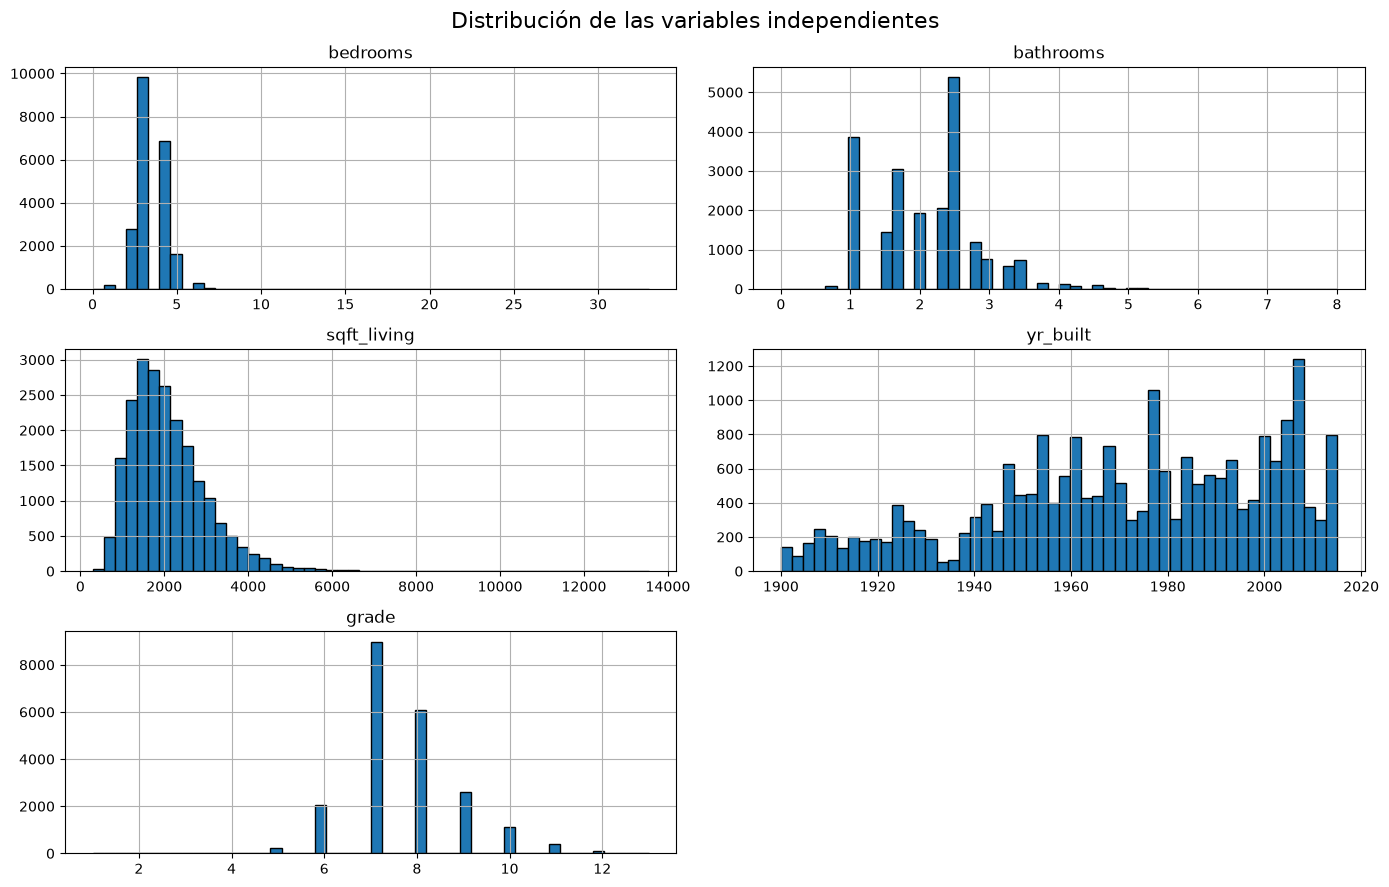

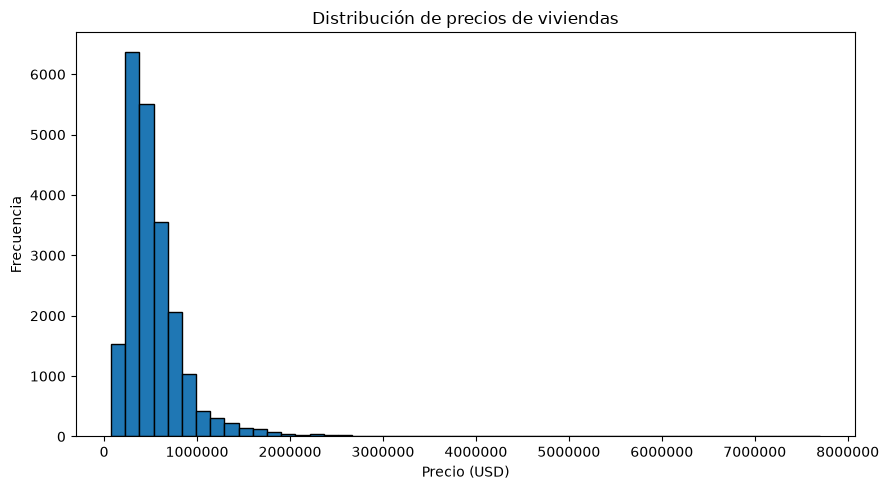

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path

Path("graficas").mkdir(exist_ok=True)

# Variables independientes
fig = X.hist(
    bins=50,
    figsize=(14, 9),
    edgecolor="black"
)

plt.suptitle(
    "Distribución de las variables independientes",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "graficas/distribucion_variables.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Variable objetivo
plt.figure(figsize=(9, 5))
plt.hist(y, bins=50, edgecolor="black")
plt.title("Distribución de precios de viviendas")
plt.xlabel("Precio (USD)")
plt.ylabel("Frecuencia")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.savefig(
    "graficas/distribucion_precios.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

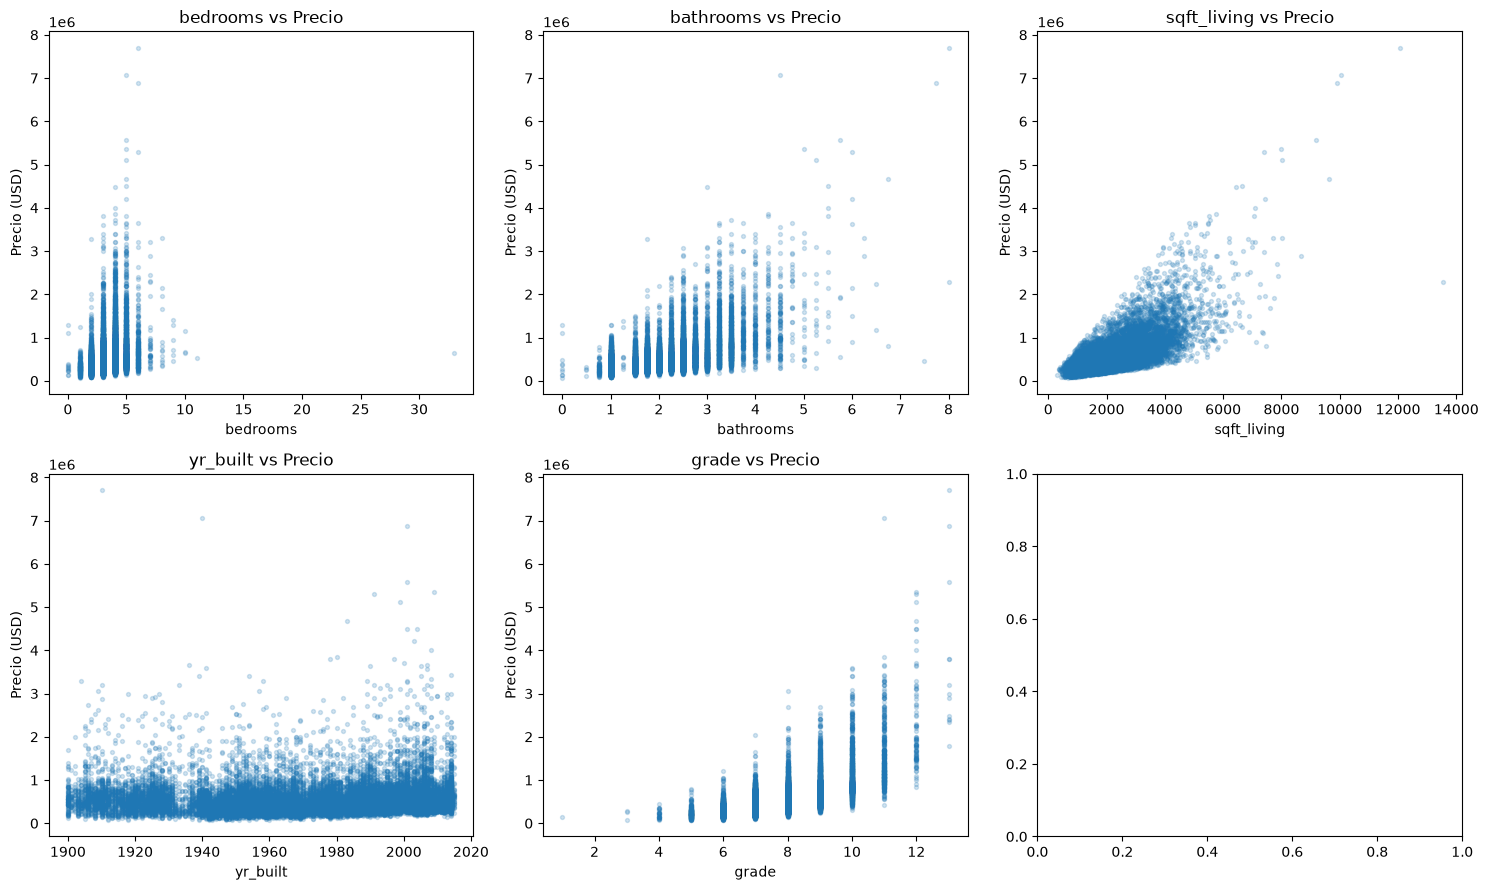

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, columna in zip(axes.flat, X.columns):
    ax.scatter(X[columna], y, alpha=0.2, s=8)
    ax.set_xlabel(columna)
    ax.set_ylabel("Precio (USD)")
    ax.set_title(f"{columna} vs Precio")

plt.tight_layout()
plt.show()

In [16]:
numeric_housing = data.select_dtypes(include=np.number)

corr_matrix = numeric_housing.corr()

corr_matrix["price"].sort_values(ascending=False)

price            1.000000
sqft_living      0.702035
grade            0.667434
sqft_above       0.605567
sqft_living15    0.585379
bathrooms        0.525138
view             0.397293
sqft_basement    0.323816
bedrooms         0.308350
lat              0.307003
waterfront       0.266369
floors           0.256794
yr_renovated     0.126434
sqft_lot         0.089661
sqft_lot15       0.082447
yr_built         0.054012
condition        0.036362
long             0.021626
id              -0.016762
zipcode         -0.053203
Name: price, dtype: float64

## 3. Modelo estadistico.



In [17]:
from sklearn.model_selection import GroupShuffleSplit

X = data[[
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "yr_built",
    "grade"
]]

y = data["price"]

groups = data["id"]

split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    split.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (17289, 5)
X_test: (4324, 5)
y_train: (17289,)
y_test: (4324,)


In [18]:
ids_train = set(groups.iloc[train_idx])
ids_test = set(groups.iloc[test_idx])

print("IDs compartidos:", len(ids_train.intersection(ids_test)))

IDs compartidos: 0


Preprocesamiento.

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [20]:
numeric_features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "yr_built",
    "grade"
]

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        )
    ]
)

Definicion de modelos.

In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

dummy_reg = DummyRegressor(
    strategy="mean"
)

lr_reg = LinearRegression()

ridge_reg = Ridge()

lasso_reg = Lasso(max_iter=10000)

rf_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

svr_reg = SVR(
    kernel="rbf",
    C=100,
    epsilon=10000,
    gamma="scale"
)

Contruccion de pipelines.

In [23]:
dummy_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", dummy_reg)
    ]
)

lr_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", lr_reg)
    ]
)

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf_reg)
    ]
)

svr_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", svr_reg)
    ]
)

In [24]:
ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", ridge_reg)
    ]
)

lasso_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", lasso_reg)
    ]
)

Validacion cruzada.

In [25]:
from sklearn.model_selection import GroupKFold, cross_validate

cv = GroupKFold(n_splits=5)

groups_train = groups.iloc[train_idx]

scoring = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

In [49]:
def evaluate_cv(model, model_name):

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        groups=groups_train,
        scoring=scoring,
        n_jobs=-1
    )

    return {
        "Modelo": model_name,
        "MAE": -scores["test_MAE"].mean(),
        "MSE": -scores["test_MSE"].mean(),
        "RMSE": -scores["test_RMSE"].mean(),
        "R2": scores["test_R2"].mean()
    }

In [50]:
import pandas as pd

cv_results = pd.DataFrame([
    evaluate_cv(
        dummy_pipeline,
        "Dummy Regressor"
    ),
    evaluate_cv(
        lr_pipeline,
        "Linear Regression"
    ),
    evaluate_cv(
        ridge_pipeline,
        "Ridge"
    ),
    evaluate_cv(
        lasso_pipeline,
        "Lasso"
    ),
    evaluate_cv(
        rf_pipeline,
        "Random Forest"
    ),
    evaluate_cv(
        svr_pipeline,
        "SVR"
    )
])

cv_results = cv_results.sort_values(
    by="RMSE",
    ascending=True
)

display(cv_results.round(4))

,Modelo,MAE,MSE,RMSE,R2
4,Random Forest,136111.0618,4.742062e+10,217705.2420,0.6423
2,Ridge,145512.4433,5.194105e+10,227706.2691,0.6106
3,Lasso,145515.6017,5.194113e+10,227706.4927,0.6106
1,Linear Regression,145515.9221,5.194114e+10,227706.5101,0.6106
5,SVR,188630.3651,1.167108e+11,341097.6705,0.1273
0,Dummy Regressor,232914.3708,1.335561e+11,365047.2894,-0.0002


# 4  Modelado predictivo con Machine Learning.

Optimizaacion de hiperparametros.

In [34]:
#RANDOM FOREST
from sklearn.model_selection import RandomizedSearchCV

param_dist_rf = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.6, 0.8, 1.0]
}

In [35]:
random_search_rf = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist_rf,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [36]:
random_search_rf.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': [0.6, 0.8, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maxim

In [37]:
print("Mejores hiperparámetros:")
print(random_search_rf.best_params_)

print(
    "Mejor RMSE:",
    -random_search_rf.best_score_
)

Mejores hiperparámetros:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 0.8, 'model__max_depth': 10}
Mejor RMSE: 209653.19556742645


In [38]:
best_rf = random_search_rf.best_estimator_

In [39]:
#SUPORT VECTOR MACHINE
param_dist_svr = {
    "model__C": [1000, 10000, 100000, 1000000],
    "model__epsilon": [1000, 10000, 25000, 50000],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

In [40]:
random_search_svr = RandomizedSearchCV(
    estimator=svr_pipeline,
    param_distributions=param_dist_svr,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [41]:
random_search_svr.fit(
    X_train,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ilon=10000))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__C': [1000, 10000, ...], 'model__epsilon': [1000, 10000, ...], 'model__gamma': ['scale', 0.01, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be 

In [42]:
print("Mejores hiperparámetros:")
print(random_search_svr.best_params_)

print(
    "Mejor RMSE:",
    -random_search_svr.best_score_
)

Mejores hiperparámetros:
{'model__gamma': 0.1, 'model__epsilon': 25000, 'model__C': 1000000}
Mejor RMSE: 216983.63231627998


In [43]:
best_svr = random_search_svr.best_estimator_

In [44]:
#Hiperparametros de Logistic Regresion
from sklearn.model_selection import GridSearchCV
import numpy as np

# Hiperparámetros de Ridge
param_grid_ridge = {
    "model__alpha": np.logspace(-3, 5, 20)
}

grid_search_ridge = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid_ridge,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

grid_search_ridge.fit(
    X_train,
    y_train,
    groups=groups_train
)

# Hiperparámetros de Lasso
param_grid_lasso = {
    "model__alpha": np.logspace(-2, 5, 20)
}

grid_search_lasso = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=param_grid_lasso,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

grid_search_lasso.fit(
    X_train,
    y_train,
    groups=groups_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'model__alpha': array([1.0000...00000000e+05])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default

In [45]:
print("RIDGE")
print("Mejores hiperparámetros:", grid_search_ridge.best_params_)
print("Mejor RMSE:", -grid_search_ridge.best_score_)

print("\nLASSO")
print("Mejores hiperparámetros:", grid_search_lasso.best_params_)
print("Mejor RMSE:", -grid_search_lasso.best_score_)

RIDGE
Mejores hiperparámetros: {'model__alpha': np.float64(112.88378916846884)}
Mejor RMSE: 227694.3784848339

LASSO
Mejores hiperparámetros: {'model__alpha': np.float64(263.6650898730355)}
Mejor RMSE: 227703.6733945245


In [46]:
best_ridge = grid_search_ridge.best_estimator_
best_lasso = grid_search_lasso.best_estimator_

In [51]:
# Evaluar los modelos con hiperparámetros optimizados

resultados_optimizados = pd.DataFrame([
    evaluate_cv(
        best_rf,
        "Random Forest Optimizado"
    ),
    evaluate_cv(
        best_svr,
        "SVR Optimizado"
    ),
    evaluate_cv(
        best_ridge,
        "Ridge Optimizado"
    ),
    evaluate_cv(
        best_lasso,
        "Lasso Optimizado"
    )
])

resultados_optimizados = resultados_optimizados.sort_values(
    by="RMSE",
    ascending=True
)

display(resultados_optimizados.round(4))

,Modelo,MAE,MSE,RMSE,R2
0,Random Forest Optimizado,130789.1884,4.397923e+10,209653.1956,0.6687
1,SVR Optimizado,129179.4076,4.729115e+10,216983.6323,0.6470
2,Ridge Optimizado,145139.1894,5.193870e+10,227694.3785,0.6106
3,Lasso Optimizado,145424.3328,5.194081e+10,227703.6734,0.6106


In [52]:
comparativa_final = pd.concat(
    [cv_results, resultados_optimizados],
    ignore_index=True
)

comparativa_final = comparativa_final.sort_values(
    by="RMSE",
    ascending=True
)

display(comparativa_final.round(4))

,Modelo,MAE,MSE,RMSE,R2
6,Random Forest Optimizado,130789.1884,4.397923e+10,209653.1956,0.6687
7,SVR Optimizado,129179.4076,4.729115e+10,216983.6323,0.6470
0,Random Forest,136111.0618,4.742062e+10,217705.2420,0.6423
8,Ridge Optimizado,145139.1894,5.193870e+10,227694.3785,0.6106
9,Lasso Optimizado,145424.3328,5.194081e+10,227703.6734,0.6106
1,Ridge,145512.4433,5.194105e+10,227706.2691,0.6106
2,Lasso,145515.6017,5.194113e+10,227706.4927,0.6106
3,Linear Regression,145515.9221,5.194114e+10,227706.5101,0.6106
4,SVR,188630.3651,1.167108e+11,341097.6705,0.1273
5,Dummy Regressor,232914.3708,1.335561e+11,365047.2894,-0.0002


# 5 Evaluacion y comparacion de modelos en Test

In [56]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import pandas as pd
import numpy as np

# Modelos a evaluar
modelos_test = {
    "Dummy Regressor": dummy_pipeline,
    "Linear Regression": lr_pipeline,
    "Random Forest Optimizado": best_rf,
    "SVR Optimizado": best_svr,
    "Ridge Optimizado": best_ridge,
    "Lasso Optimizado": best_lasso
}

resultados_test = []

for nombre, modelo in modelos_test.items():

    # Entrenar con todos los datos de Train
    modelo_entrenado = clone(modelo)
    modelo_entrenado.fit(X_train, y_train)

    # Predicciones en Test
    y_pred = modelo_entrenado.predict(X_test)

    # Calcular métricas
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    resultados_test.append({
        "Modelo": nombre,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Crear tabla comparativa
comparativa_test = pd.DataFrame(resultados_test)

comparativa_test = comparativa_test.sort_values(
    by="RMSE",
    ascending=True
)

display(comparativa_test.round(4))

,Modelo,MAE,MSE,RMSE,R2
2,Random Forest Optimizado,130901.2154,4.057324e+10,201428.0129,0.7095
4,Ridge Optimizado,130901.2154,4.057324e+10,201428.0129,0.7095
5,Lasso Optimizado,130901.2154,4.057324e+10,201428.0129,0.7095
3,SVR Optimizado,130239.3067,4.606338e+10,214623.8134,0.6702
1,Linear Regression,146812.8622,5.269829e+10,229561.0854,0.6227
0,Dummy Regressor,236440.6271,1.397116e+11,373780.2007,-0.0003


In [60]:
best_rf = random_search_rf.best_estimator_

y_pred_test = best_rf.predict(X_test)

In [59]:
import pandas as pd

# Resultados de Random Forest optimizado en CV
rf_cv = resultados_optimizados[
    resultados_optimizados["Modelo"] == "Random Forest Optimizado"
].iloc[0]

# Resultados de Random Forest optimizado en Test
rf_test = comparativa_test[
    comparativa_test["Modelo"] == "Random Forest Optimizado"
].iloc[0]

# Tabla comparativa
comparacion_cv_test = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "RMSE", "R2"],
    "CV": [
        rf_cv["MAE"],
        rf_cv["MSE"],
        rf_cv["RMSE"],
        rf_cv["R2"]
    ],
    "Test": [
        rf_test["MAE"],
        rf_test["MSE"],
        rf_test["RMSE"],
        rf_test["R2"]
    ]
})

display(comparacion_cv_test.round(4))

,Métrica,CV,Test
0,MAE,1.307892e+05,1.309012e+05
1,MSE,4.397923e+10,4.057324e+10
2,RMSE,2.096532e+05,2.014280e+05
3,R2,6.687000e-01,7.095000e-01


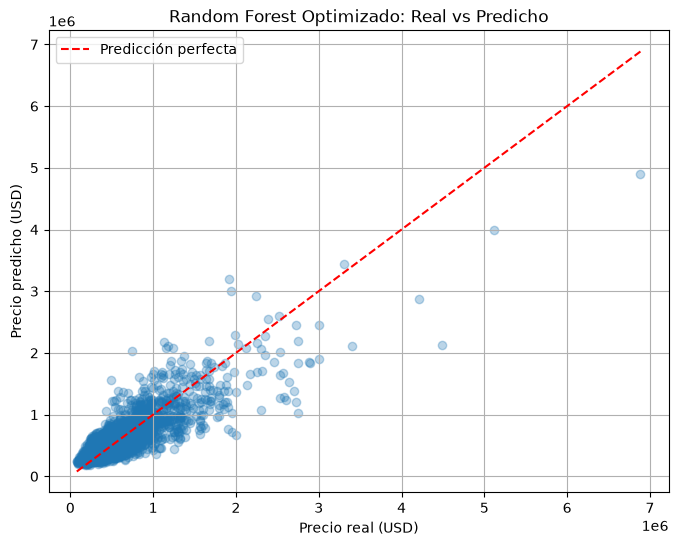

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_test,
    alpha=0.3
)

limites = [
    min(y_test.min(), y_pred_test.min()),
    max(y_test.max(), y_pred_test.max())
]

plt.plot(
    limites,
    limites,
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.title("Random Forest Optimizado: Real vs Predicho")
plt.legend()
plt.grid(True)
plt.show()

Guardar el modelo.

In [ ]:
import joblib
modelo_final = random_search_rf.best_estimator_
joblib.dump(modelo_final, "modelo_viviendas.pkl")

Modelo guardado correctamente


In [ ]:
import joblib
modelo_cargado = joblib.load("modelo_viviendas.pkl")
vivienda = X_test.iloc[[0]]
precio_estimado = modelo_cargado.predict(vivienda)

print("Precio real:", y_test.iloc[0])
print("Precio estimado:", precio_estimado[0])

Precio real: 510000.0
Precio estimado: 435054.1634679649
